# Examen — Módulo 1: Preparación de datos
**Aprendizaje Supervisado · Evaluación de las sesiones 1–3** (EDA, preprocesamiento, ingeniería y selección de variables)

**Instrucciones**

- Trabajo **individual**. Duración sugerida: **120 minutos**. Material permitido: tus notas, la presentación y la documentación oficial de pandas, scikit-learn y matplotlib.
- Escribe tu nombre en la primera celda de código (`NOMBRE`).
- Sustituye cada `...` (marcado con ✏️) por tu código. En las preguntas con **“Respuesta:”**, escribe tu explicación en la celda de texto que sigue (editando la celda de Markdown).
- Antes de entregar, ejecuta **Kernel → Reiniciar y ejecutar todo**; el notebook debe correr de principio a fin sin errores.
- Los datos son simulados y se generan con semilla fija: tus resultados deben ser reproducibles.
- Se evalúa tanto el **código** como la **calidad de la justificación**. Las respuestas escritas deben ser breves y precisas.

| Parte | Tema | Puntos |
|---|---|---|
| I | Análisis exploratorio de datos | 30 |
| II | Preprocesamiento de datos | 35 |
| III | Ingeniería y selección de variables | 35 |
| | **Total** | **100** |


In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, cross_val_score, KFold, StratifiedKFold
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import (StandardScaler, MinMaxScaler, RobustScaler, OneHotEncoder,
                                   OrdinalEncoder, PolynomialFeatures)
from sklearn.linear_model import Ridge, LogisticRegression
from sklearn.feature_selection import (VarianceThreshold, SelectKBest, f_classif, mutual_info_classif,
                                       RFE, RFECV, SelectFromModel)
from sklearn.metrics import mean_squared_error

warnings.filterwarnings("ignore")
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": .3})

NOMBRE = "Julian Emiliano Ortiz Rivero"

In [2]:
# ---------------------------------------------------------------------------------------------
# Generadores de datos (NO los modifiques; no necesitas leerlos para resolver el examen)
# ---------------------------------------------------------------------------------------------
def genera_viviendas(n=1200, seed=2026):
    """Viviendas en venta en una ciudad (datos simulados). Precio en miles de pesos."""
    r = np.random.default_rng(seed)
    zona = r.choice(["Norte", "Centro", "Poniente", "Oriente", "Sur", "Costa"], n, p=[.30, .15, .22, .14, .17, .02])
    acab = r.choice(["Básico", "Medio", "Alto", "Premium"], n, p=[.30, .40, .22, .08])
    sup = np.exp(r.normal(np.log(110), .38, n)).round(0)
    rec = np.clip(np.round(sup / 45 + r.normal(0, .6, n)), 1, 6).astype(int)
    ant = np.clip(r.gamma(1.6, 9, n), 0, 70).round(0)
    dist = np.round(r.gamma(2.2, 3.2, n), 1)
    zef = pd.Series(zona).map({"Norte": .25, "Centro": .05, "Poniente": .10, "Oriente": -.20, "Sur": -.30, "Costa": .55}).values
    aef = pd.Series(acab).map({"Básico": 0, "Medio": .18, "Alto": .40, "Premium": .75}).values
    lp = 1.2 + .85 * np.log(sup) + zef + aef - .008 * ant - .035 * dist + .04 * rec + r.normal(0, .17, n)
    precio = (np.exp(lp) * 25).round(0)
    idx = r.choice(n, 10, replace=False)
    precio[idx] *= r.uniform(3.5, 6, 10)
    df = pd.DataFrame(dict(zona=zona, acabados=acab, superficie_m2=sup, recamaras=rec,
                           antiguedad_anios=ant, dist_centro_km=dist, precio_miles=precio.round(0)))
    pm = np.where(np.isin(zona, ["Sur", "Oriente"]), .22, .04)
    df.loc[r.random(n) < pm, "antiguedad_anios"] = np.nan
    df.loc[r.random(n) < .04, "superficie_m2"] = np.nan
    return df


def genera_biomarcadores(n=400, seed=7):
    """400 pacientes, 26 mediciones de laboratorio y un diagnóstico y ∈ {0, 1} (datos simulados)."""
    r = np.random.default_rng(seed)
    y = r.integers(0, 2, n)
    s = 2 * y - 1
    a = r.normal(0.9 * s, 1.0)
    b = 100 + 15 * r.normal(0.6 * s, 1.0)
    c = 0.02 * r.normal(0.8 * s, 1.0)
    cuad = np.where(y == 1, r.choice([-1, 1], n) * r.normal(1.6, .35, n), r.normal(0, .45, n))
    a_copia = a + r.normal(0, .15, n)
    casi = 5 + 1e-3 * r.normal(0, 1, n)
    ruido = r.normal(0, 1, (n, 20)) * r.choice([1, 1, 1, 10, 50], 20)
    cols = {"lin_a": a, "lin_b": b, "lin_c": c, "cuad": cuad, "lin_a_copia": a_copia, "casi_const": casi}
    for i in range(20):
        cols[f"ruido_{i + 1:02d}"] = ruido[:, i]
    return pd.DataFrame(cols), pd.Series(y, name="y")


---
## Parte I — Análisis exploratorio de datos (30 puntos)

Trabajarás con `viv`: **1 200 viviendas en venta** de una ciudad (datos simulados).
Variables: `zona` y `acabados` (categóricas; `acabados` es ordinal: Básico < Medio < Alto < Premium), `superficie_m2`, `recamaras`,
`antiguedad_anios`, `dist_centro_km` y el objetivo `precio_miles` (miles de pesos). Hay valores faltantes.

In [3]:
viv = genera_viviendas()
NUM = ["superficie_m2", "recamaras", "antiguedad_anios", "dist_centro_km", "precio_miles"]
print(viv.shape)
viv.head()

(1200, 7)


,zona,acabados,superficie_m2,recamaras,antiguedad_anios,dist_centro_km,precio_miles
0,Norte,Medio,74.0,2,25.0,8.1,4289.0
1,Poniente,Medio,166.0,4,14.0,9.4,7465.0
2,Poniente,Premium,211.0,4,7.0,2.1,16996.0
3,Centro,Medio,153.0,4,30.0,3.4,6301.0
4,Centro,Básico,101.0,2,0.0,9.5,4444.0


### Pregunta I.1 · Asimetría y curtosis  *(4 pts)*

Calcula la **asimetría** y la **curtosis (excedente)** de las cinco variables numéricas `NUM` y guarda en `mas_asimetrica` el *nombre* de la variable con mayor asimetría.

In [4]:
asim = viv[NUM].skew()
curt = viv[NUM].kurt()
mas_asimetrica = asim.idxmax()

print(pd.DataFrame({"asimetría": asim, "curtosis": curt}).round(2))
print("Más asimétrica:", mas_asimetrica)

                  asimetría  curtosis
superficie_m2          1.00      1.42
recamaras              0.57      0.10
antiguedad_anios       1.41      2.36
dist_centro_km         1.16      1.87
precio_miles           3.38     22.95
Más asimétrica: precio_miles


### Pregunta I.2 · Interpretar la forma de `precio_miles`  *(3 pts)*

Observa la media y la mediana del precio y su histograma. En **3 a 5 líneas**: ¿qué forma tiene la distribución según la asimetría y la curtosis? ¿Qué medida de centro describiría mejor un precio “típico” y por qué?

media = 5,271   mediana = 4,504


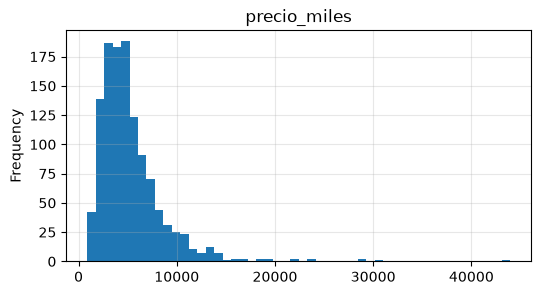

In [5]:
print(f"media = {viv.precio_miles.mean():,.0f}   mediana = {viv.precio_miles.median():,.0f}")
viv.precio_miles.plot.hist(bins=50, figsize=(6, 3), title="precio_miles");

**Respuesta:**

El precio tiene asimetría positiva (3.38) y curtosis alta (22.95), así que presenta una cola
derecha marcada y varios valores extremos. La media es 5 271 y la mediana 4 504. Usaría la mediana
para representar un precio típico porque cambia menos ante las viviendas más caras.


### Pregunta I.3 · Regla del IQR  *(5 pts)*

Escribe la función `atipicos_iqr(s, k=1.5)` que, dada una Series `s`, devuelva una Series booleana que marque como atípicos los valores fuera de $[Q_1 - k\,\mathrm{IQR},\; Q_3 + k\,\mathrm{IQR}]$ (ignora los `NaN`). Después cuenta los atípicos de cada variable de `NUM`.

In [6]:
def atipicos_iqr(s, k=1.5):
    s = s.dropna()
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    return (s < q1 - k * iqr) | (s > q3 + k * iqr)


n_atip = {variable: int(atipicos_iqr(viv[variable]).sum()) for variable in NUM}
print(n_atip)

{'superficie_m2': 20, 'recamaras': 78, 'antiguedad_anios': 37, 'dist_centro_km': 25, 'precio_miles': 57}


### Pregunta I.4 · El logaritmo y los atípicos  *(4 pts)*

Crea `log_precio = np.log(viv.precio_miles)`, calcula su asimetría y cuántos atípicos marca la regla del IQR. Luego responde en **3 a 4 líneas**: ¿la transformación resolvió el problema de los atípicos? Entre eliminarlos, dejarlos o transformarlos, ¿qué harías con las viviendas más caras y por qué? (Recuerda cómo se generó el dato: hay viviendas con precios muy superiores al de su tipo.)

In [7]:
log_precio = np.log(viv.precio_miles)
asim_log = log_precio.skew()
n_atip_log = int(atipicos_iqr(log_precio).sum())
print(f"asimetría: {asim_log:.2f}   atípicos: {n_atip_log}")

asimetría: 0.22   atípicos: 14


**Respuesta:**

El logaritmo reduce la asimetría de 3.38 a 0.22 y los atípicos de 57 a 14, pero no los elimina por
completo. No borraría automáticamente las viviendas más caras porque pueden ser ventas reales.
Usaría el logaritmo y revisaría esos registros para separar precios válidos de errores de captura.


### Pregunta I.5 · Pearson, Spearman y transformaciones  *(6 pts)*

Calcula, entre el precio y `superficie_m2`, cuatro coeficientes y guárdalos en el dict `r`:
`"pearson_crudo"` (precio sin transformar), `"pearson_log"` (con `log_precio`), `"spearman_crudo"` y `"spearman_log"`.
Después explica en **3 a 4 líneas**: (a) por qué `spearman_crudo` y `spearman_log` coinciden, y (b) por qué `pearson_crudo` y `pearson_log` no.

In [8]:
d = pd.DataFrame({"precio": viv.precio_miles, "log_precio": log_precio, "superficie": viv.superficie_m2})

r = {
    "pearson_crudo": d["precio"].corr(d["superficie"]),
    "pearson_log": d["log_precio"].corr(d["superficie"]),
    "spearman_crudo": d["precio"].corr(d["superficie"], method="spearman"),
    "spearman_log": d["log_precio"].corr(d["superficie"], method="spearman"),
}
print({k: round(v, 3) for k, v in r.items()})

{'pearson_crudo': np.float64(0.546), 'pearson_log': np.float64(0.616), 'spearman_crudo': np.float64(0.637), 'spearman_log': np.float64(0.637)}


**Respuesta:**

Spearman vale 0.637 en ambos casos porque el logaritmo conserva el orden de los precios. Pearson
sube de 0.546 a 0.616 porque usa las distancias entre valores y el logaritmo comprime la cola
derecha. Así los precios extremos tienen menos influencia en el coeficiente.


### Pregunta I.6 · Verdadero o falso  *(4 pts)*

Marca cada afirmación como `True` (verdadera) o `False` (falsa). Cada acierto vale 1 punto; no hay penalización por error.

- **a)** Si el coeficiente de correlación de Pearson entre $X$ e $Y$ es 0, entonces $X$ e $Y$ son independientes.
- **b)** La mediana es más robusta que la media frente a valores atípicos.
- **c)** Una correlación de 0.9 entre las ventas de helado y los ahogamientos demuestra que el helado causa ahogamientos.
- **d)** Una curtosis excedente positiva indica colas más pesadas que las de una distribución normal.

In [9]:
resp_VF = {"a": False, "b": True, "c": False, "d": True}

### Pregunta I.7 · Matriz de correlación y multicolinealidad  *(4 pts)*

Calcula la matriz de correlación de Pearson de `superficie_m2`, `recamaras`, `antiguedad_anios`, `dist_centro_km` y `log_precio`, dibújala como mapa de calor (con barra de color y etiquetas) y guarda en `par` la tupla con los nombres de las **dos variables explicativas** (sin contar `log_precio`) más correlacionadas entre sí en valor absoluto. En **2 a 3 líneas**: ¿por qué sería un problema meter ambas en una regresión lineal y qué harías?

('superficie_m2', 'recamaras')


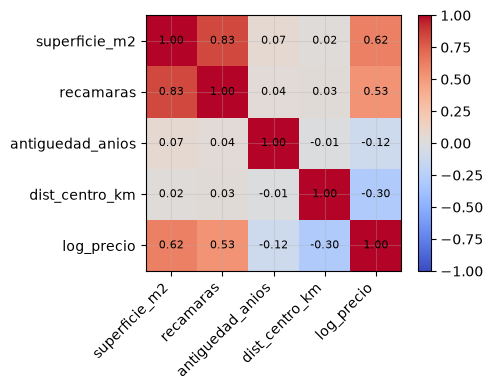

In [10]:
cols = ["superficie_m2", "recamaras", "antiguedad_anios", "dist_centro_km"]
datos_corr = viv[cols].copy()
datos_corr["log_precio"] = log_precio
C = datos_corr.corr()

fig, ax = plt.subplots(figsize=(5, 4))
imagen = ax.imshow(C, cmap="coolwarm", vmin=-1, vmax=1)
fig.colorbar(imagen, ax=ax)
ax.set_xticks(range(len(C.columns)), C.columns, rotation=45, ha="right")
ax.set_yticks(range(len(C.index)), C.index)
for i in range(len(C.index)):
    for j in range(len(C.columns)):
        ax.text(j, i, f"{C.iloc[i, j]:.2f}", ha="center", va="center", fontsize=8)
plt.tight_layout()

cor_exp = C.loc[cols, cols].abs()
triangulo = cor_exp.where(np.triu(np.ones(cor_exp.shape), k=1).astype(bool))
par = triangulo.stack().idxmax()
print(par)

**Respuesta:**

`superficie_m2` y `recamaras` son las explicativas más relacionadas, con una correlación de 0.829.
Incluir ambas puede volver inestables sus coeficientes y dificultar su interpretación. Compararía
el desempeño al retirar una o usaría regularización.


---
## Parte II — Preprocesamiento de datos (35 puntos)

Seguimos con el conjunto `viv`. Ahora el objetivo es **predecir `log(precio_miles)`** con un modelo lineal, cuidando el preprocesamiento.

### Pregunta II.1 · Cuantificar los valores faltantes  *(4 pts)*

Calcula (a) el número y el porcentaje de valores faltantes por columna y (b) la **proporción de faltantes por `zona`** para `antiguedad_anios` y `superficie_m2`.

In [11]:
faltantes = pd.DataFrame({"n": viv.isna().sum(), "%": 100 * viv.isna().mean()})
falt_por_zona = viv.groupby("zona")[["antiguedad_anios", "superficie_m2"]].agg(lambda s: s.isna().mean())

print(faltantes[faltantes["n"] > 0])
print((100 * falt_por_zona).round(1))

                    n         %
superficie_m2      62  5.166667
antiguedad_anios  107  8.916667
          antiguedad_anios  superficie_m2
zona                                     
Centro                 2.2            6.7
Costa                  0.0            4.0
Norte                  3.0            4.0
Oriente               19.1            4.4
Poniente               4.4            5.2
Sur                   21.6            6.6


### Pregunta II.2 · Mecanismo de los faltantes  *(3 pts)*

Con lo que observaste en II.1, ¿qué mecanismo (MCAR, MAR o MNAR) es más plausible para `antiguedad_anios` y cuál para `superficie_m2`? Justifica con los números. ¿Qué riesgo habría al **borrar** las filas incompletas?

**Respuesta:**

Los faltantes de `antiguedad_anios` son compatibles con MAR: llegan a 21.6 % en Sur y 19.1 % en
Oriente, mientras las demás zonas quedan entre 0 % y 4.4 %. Los de `superficie_m2` se parecen más
a MCAR porque van de 4.0 % a 6.7 % sin un patrón claro. Borrar filas incompletas reduciría la
muestra y dejaría menos viviendas de Sur y Oriente.


### Pregunta II.3 · División entrenamiento / prueba  *(5 pts)*

Define `X = viv` sin `precio_miles` e `y = log_precio`. Separa 80 % para entrenamiento y 20 % para prueba (`random_state=0`) **estratificando por `zona`**, y muestra la proporción de cada zona en `X_train` y `X_test`. En **2 líneas**: ¿por qué conviene estratificar en este conjunto?

In [12]:
X = viv.drop(columns="precio_miles")
y = log_precio
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=0, stratify=X["zona"]
)

prop = pd.DataFrame({
    "train": X_train["zona"].value_counts(normalize=True),
    "test": X_test["zona"].value_counts(normalize=True),
}).fillna(0)
print((100 * prop).round(1))

          train  test
zona                 
Norte      27.4  27.5
Poniente   22.5  22.5
Sur        17.7  17.9
Oriente    15.3  15.0
Centro     15.0  15.0
Costa       2.1   2.1


**Respuesta:**

Conviene estratificar porque Costa representa una parte pequeña del conjunto. Así se mantienen
proporciones similares de cada zona en entrenamiento y prueba.


### Pregunta II.4 · Detectar fuga de datos  *(4 pts)*

Un compañero escribe este código para “preparar los datos” y luego evalúa con validación cruzada:

```python
X_num = viv[["superficie_m2", "antiguedad_anios", "dist_centro_km"]]
X_num = SimpleImputer(strategy="mean").fit_transform(X_num)      # (1)
X_num = StandardScaler().fit_transform(X_num)                    # (2)
scores = cross_val_score(Ridge(), X_num, log_precio, cv=5)       # (3)
```

Explica **qué información se filtra** en los pasos (1) y (2), por qué es un problema y cómo lo corregirías (en palabras, sin escribir todo el código).

**Respuesta:**

La media de imputación y los parámetros del escalador se calculan con observaciones que luego
forman parte de cada bloque de validación. Esa información adelanta la distribución de los datos
que deberían permanecer sin ver y vuelve optimista la evaluación. La corrección es colocar
imputación, escalamiento y modelo dentro de un `Pipeline` evaluado completo en cada partición.


### Pregunta II.5 · Pipeline de preprocesamiento + modelo  *(10 pts)*

Construye un `Pipeline` que, **sin fuga de datos**, haga:

1. Variables numéricas (`superficie_m2`, `recamaras`, `antiguedad_anios`, `dist_centro_km`): imputación y un escalador de tu elección.
2. Variable nominal `zona`: imputación (por si acaso) y codificación *one-hot* **tolerante a categorías no vistas**.
3. Variable ordinal `acabados`: codificación ordinal respetando Básico < Medio < Alto < Premium.
4. Modelo: `Ridge(alpha=1.0)`.

Evalúa con validación cruzada de 5 particiones **solo con el entrenamiento** (reporta el RMSE medio sobre `log(precio)`), ajusta con todo el entrenamiento y reporta el RMSE en prueba. Justifica en 2 líneas tu elección de imputador y escalador.

In [13]:
NUM_X = ["superficie_m2", "recamaras", "antiguedad_anios", "dist_centro_km"]
NOM = ["zona"]
ORD = ["acabados"]

num_pipe = Pipeline([
    ("imputacion", SimpleImputer(strategy="median")),
    ("escalado", RobustScaler()),
])
nom_pipe = Pipeline([
    ("imputacion", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore")),
])
ord_pipe = OrdinalEncoder(
    categories=[["Básico", "Medio", "Alto", "Premium"]],
    handle_unknown="use_encoded_value",
    unknown_value=-1,
)

pre = ColumnTransformer([
    ("numericas", num_pipe, NUM_X),
    ("nominal", nom_pipe, NOM),
    ("ordinal", ord_pipe, ORD),
])
modelo = Pipeline([("preprocesamiento", pre), ("ridge", Ridge(alpha=1.0))])

cv = KFold(5, shuffle=True, random_state=0)
rmse_cv = -cross_val_score(
    modelo, X_train, y_train, cv=cv, scoring="neg_root_mean_squared_error"
).mean()
modelo.fit(X_train, y_train)
rmse_test = mean_squared_error(y_test, modelo.predict(X_test)) ** 0.5

print(f"RMSE CV = {rmse_cv:.3f}    RMSE prueba = {rmse_test:.3f}")

RMSE CV = 0.254    RMSE prueba = 0.251


**Respuesta:**

Elegí imputación por mediana porque las variables numéricas tienen asimetría y valores extremos.
Usé `RobustScaler` porque se apoya en la mediana y el IQR. El pipeline obtuvo RMSE 0.254 en
validación y 0.251 en prueba.


### Pregunta II.6 · Escalador y atípicos  *(4 pts)*

Toma `superficie_m2` del conjunto de entrenamiento (imputando antes los `NaN` con la mediana) y **añade un registro mal capturado de 5 000 m²**. Aplica `StandardScaler` y `RobustScaler`. Para cada resultado calcula el **rango intercuartílico** de la variable escalada y su **valor absoluto máximo**. En **2 a 3 líneas**: ¿qué escalador es más sensible a los atípicos y por qué? ¿Para qué tipo de modelos importa escalar?

In [14]:
s = X_train["superficie_m2"].fillna(X_train["superficie_m2"].median())
s = pd.concat([s, pd.Series([5000.0])], ignore_index=True).to_frame()

z_std = StandardScaler().fit_transform(s).ravel()
z_rob = RobustScaler().fit_transform(s).ravel()

def resumen(z):
    q1, q3 = np.percentile(z, [25, 75])
    return {"IQR": round(q3 - q1, 3), "|max|": round(np.abs(z).max(), 2)}

print("Standard:", resumen(z_std))
print("Robust:  ", resumen(z_rob))

Standard: {'IQR': np.float64(0.354), '|max|': np.float64(29.78)}
Robust:   {'IQR': np.float64(1.0), '|max|': np.float64(84.28)}


**Respuesta:**

`StandardScaler` es más sensible: el dato de 5 000 m² comprime el IQR a 0.354. Con `RobustScaler`
el IQR se mantiene en 1, aunque el extremo alcanza 84.28. Escalar importa sobre todo en modelos
basados en distancias, gradientes o penalizaciones.


### Pregunta II.7 · Categorías no vistas y codificación  *(5 pts)*

Ajusta un `OneHotEncoder` **con el valor por defecto** y otro con `handle_unknown="ignore"` usando solo las filas de `X_train` cuya `zona` **no** sea `Costa`. Luego transforma una vivienda de `Costa` con cada uno: captura el error del primero (`msg_error`) y guarda la fila resultante del segundo (`fila_ignore`).
En **2 líneas**: ¿qué problema aparece si en lugar de *one-hot* codificas `zona` con enteros (0, 1, 2, …) en un modelo lineal?

In [15]:
sin_costa = X_train.loc[X_train["zona"] != "Costa", ["zona"]]
nueva = pd.DataFrame({"zona": ["Costa"]})

msg_error = None
try:
    OneHotEncoder().fit(sin_costa).transform(nueva)
except ValueError as e:
    msg_error = str(e)[:90]

codificador = OneHotEncoder(handle_unknown="ignore")
fila_ignore = codificador.fit(sin_costa).transform(nueva).toarray()

print("Error:", msg_error)
print("Fila con ignore:", fila_ignore)

Error: Found unknown categories ['Costa'] in column 0 during transform
Fila con ignore: [[0. 0. 0. 0. 0.]]


**Respuesta:**

El codificador predeterminado falla porque `Costa` no apareció durante el ajuste. Con enteros se
impondría un orden y distancias inexistentes entre zonas, lo que distorsionaría un modelo lineal.


---
## Parte III — Ingeniería y selección de variables (35 puntos)

Ahora `X_b` contiene **26 mediciones de laboratorio** de 400 pacientes y `y_b` es un diagnóstico binario (0/1). Algunas variables
son útiles y otras no. Toda evaluación de desempeño debe hacerse con **validación cruzada** (`cv_b`) y, cuando haya selección o
escalado, **dentro de un `Pipeline`**.

In [16]:
X_b, y_b = genera_biomarcadores()
cv_b = StratifiedKFold(5, shuffle=True, random_state=0)
print(X_b.shape, y_b.value_counts().to_dict())

(400, 26) {1: 213, 0: 187}


### Pregunta III.1 · Umbral de varianza  *(5 pts)*

Aplica `VarianceThreshold(threshold=0.01)` a `X_b` en su escala original y guarda en `quitadas_crudo` la lista de variables eliminadas. Repite con `X_b` estandarizada y guarda en `n_quitadas_std` cuántas elimina. En **3 líneas**: ¿qué enseñan los dos resultados sobre el umbral de varianza como criterio de selección?

In [17]:
selector_crudo = VarianceThreshold(threshold=0.01).fit(X_b)
quitadas_crudo = X_b.columns[~selector_crudo.get_support()].tolist()

X_b_std = StandardScaler().fit_transform(X_b)
selector_std = VarianceThreshold(threshold=0.01).fit(X_b_std)
n_quitadas_std = int((~selector_std.get_support()).sum())

print("Original:", quitadas_crudo)
print("Estandarizada:", n_quitadas_std)

Original: ['lin_c', 'casi_const']
Estandarizada: 0


**Respuesta:**

En la escala original se eliminan `lin_c` y `casi_const`. `lin_c` sí contiene señal, pero su unidad
hace que tenga poca varianza. Tras estandarizar no se elimina ninguna. El umbral depende de la
escala y no mide la relación con el objetivo.


### Pregunta III.2 · Filtros: F de ANOVA vs. información mutua  *(6 pts)*

Selecciona las 5 mejores variables con `SelectKBest` usando (a) `f_classif` y (b) `mutual_info_classif` (con `random_state=0`). Guarda los nombres en `sel_F` y `sel_MI`. En **3 a 4 líneas**: ¿qué variable distingue ambos resultados y por qué un filtro la ve y el otro no? (Pista: calcula la correlación de Pearson de esa variable con `y_b`.)

In [18]:
selector_F = SelectKBest(f_classif, k=5).fit(X_b, y_b)
sel_F = X_b.columns[selector_F.get_support()].tolist()

selector_MI = SelectKBest(
    lambda X, y: mutual_info_classif(X, y, random_state=0), k=5
).fit(X_b, y_b)
sel_MI = X_b.columns[selector_MI.get_support()].tolist()

print("F :", sel_F)
print("MI:", sel_MI)

F :

 ['lin_a', 'lin_b', 'lin_c', 'lin_a_copia', 'ruido_08']
MI: ['lin_a', 'lin_b', 'lin_c', 'cuad', 'lin_a_copia']


**Respuesta:**

ANOVA selecciona `ruido_08`, mientras información mutua recupera `cuad`. La variable `cuad` separa
las clases de forma no lineal y su correlación de Pearson con `y_b` es -0.024. El estadístico F no
detecta bien ese patrón, pero información mutua sí encuentra la dependencia.


### Pregunta III.3 · Redundancia  *(4 pts)*

Calcula la matriz de correlación de las variables de `sel_MI` y guarda en `par_redundante` el par con mayor correlación absoluta. En **2 líneas**: ¿por qué un filtro univariado no evita este problema y qué harías al respecto?

In [19]:
R = X_b[sel_MI].corr()
triangulo = R.abs().where(np.triu(np.ones(R.shape), k=1).astype(bool))
par_redundante = triangulo.stack().idxmax()
print(par_redundante, round(abs(R.loc[par_redundante[0], par_redundante[1]]), 3))

('lin_a', 'lin_a_copia') 0.994


**Respuesta:**

El par redundante es `lin_a` con `lin_a_copia`, cuya correlación es 0.994. El filtro puntúa cada
variable por separado y puede elegir ambas aunque repitan información. Conservaría una del par o
usaría un método multivariado.


### Pregunta III.4 · Envoltura: RFE y RFECV  *(6 pts)*

Con regresión logística (`max_iter=1000`) y **estandarizando dentro del pipeline**:
(a) usa `RFE` para conservar 6 variables y guarda sus nombres en `sel_rfe`;
(b) usa `RFECV` (con `cv_b` y `scoring="accuracy"`) y guarda en `k_opt` el número de variables que recomienda.
En **3 líneas**: ¿`RFE` con regresión logística recupera `cuad`? ¿Por qué? ¿Qué costo tiene frente a un filtro?

In [20]:
pipe_rfe = Pipeline([
    ("escalador", StandardScaler()),
    ("rfe", RFE(LogisticRegression(max_iter=1000), n_features_to_select=6)),
])
pipe_rfe.fit(X_b, y_b)
sel_rfe = X_b.columns[pipe_rfe.named_steps["rfe"].get_support()].tolist()

pipe_cv = Pipeline([
    ("escalador", StandardScaler()),
    ("rfecv", RFECV(LogisticRegression(max_iter=1000), cv=cv_b, scoring="accuracy")),
])
pipe_cv.fit(X_b, y_b)
k_opt = int(pipe_cv.named_steps["rfecv"].n_features_)

print(sel_rfe)
print("k óptimo:", k_opt)

['lin_a', 'lin_b', 'lin_c', 'lin_a_copia', 'ruido_06', 'ruido_19']
k óptimo: 4


**Respuesta:**

RFE conserva seis variables, pero no recupera `cuad` porque la regresión logística busca una
frontera lineal. RFECV recomienda cuatro variables. Frente a un filtro, RFE cuesta más porque
ajusta el modelo repetidas veces mientras elimina columnas.


### Pregunta III.5 · Selección integrada: regresión logística L1  *(4 pts)*

Para $C \in \{0.005,\,0.01,\,0.05,\,0.1,\,1\}$, ajusta `LogisticRegression(penalty="l1", solver="liblinear", C=C)` sobre `X_b` estandarizada, usando `SelectFromModel`, y guarda en `n_sel` un dict `{C: número de variables seleccionadas}`. En **2 líneas**: ¿cómo se relaciona $C$ con el número de variables y qué ventaja tiene este método frente a un filtro?

In [21]:
n_sel = {}
for C in [0.005, 0.01, 0.05, 0.1, 1]:
    seleccion = SelectFromModel(
        LogisticRegression(penalty="l1", solver="liblinear", C=C, max_iter=1000)
    )
    pipe_l1 = Pipeline([("escalador", StandardScaler()), ("seleccion", seleccion)])
    pipe_l1.fit(X_b, y_b)
    n_sel[C] = int(pipe_l1.named_steps["seleccion"].get_support().sum())
print(n_sel)

{0.005: 0, 0.01: 2, 0.05: 4, 0.1: 4, 1: 23}


**Respuesta:**

Con `C` de 0.005, 0.01, 0.05, 0.1 y 1 se seleccionan 0, 2, 4, 4 y 23 variables. Un `C` mayor reduce
la penalización y deja más coeficientes activos. Este método considera el efecto conjunto dentro
del modelo, a diferencia de un filtro que evalúa cada variable por separado.


### Pregunta III.6 · Fuga de datos en la selección de variables  *(6 pts)*

Generamos datos de **puro ruido**: `Xn` con 100 filas y 1 000 columnas aleatorias, y `yn` aleatoria; por construcción, ningún modelo puede predecir `yn` mejor que el azar (exactitud ≈ 0.5).

(a) **Mal:** selecciona las 20 mejores columnas con `SelectKBest(f_classif)` usando *todos* los datos y luego evalúa una regresión logística con validación cruzada → `acc_mal`.
(b) **Bien:** pon la selección y el modelo en un `Pipeline` y evalúa con la misma validación cruzada → `acc_bien`.
En **3 líneas**: explica la diferencia y qué regla de la receta de selección se viola en (a).

In [22]:
rng = np.random.default_rng(0)
Xn = rng.normal(size=(100, 1000))
yn = rng.integers(0, 2, 100)
cv_n = StratifiedKFold(5, shuffle=True, random_state=0)

selector_ruido = SelectKBest(f_classif, k=20).fit(Xn, yn)
Xn_elegido = selector_ruido.transform(Xn)
acc_mal = cross_val_score(
    LogisticRegression(max_iter=1000), Xn_elegido, yn, cv=cv_n, scoring="accuracy"
).mean()

pipe_ruido = make_pipeline(
    SelectKBest(f_classif, k=20), LogisticRegression(max_iter=1000)
)
acc_bien = cross_val_score(pipe_ruido, Xn, yn, cv=cv_n, scoring="accuracy").mean()
print(f"Mal: {acc_mal:.2f}    Bien: {acc_bien:.2f}")

Mal: 0.85    Bien: 0.57


**Respuesta:**

La selección externa usa las etiquetas de todo el conjunto antes de validar y alcanza 0.85 al
escoger asociaciones accidentales del ruido. En el pipeline, cada pliegue selecciona usando solo
su entrenamiento y la exactitud baja a 0.57, cerca del azar. La selección siempre debe repetirse
dentro de cada partición.


### Pregunta III.7 · Ingeniería de variables y polinomios  *(4 pts)*

(a) Agrega a `X_b` la variable `cuad_2 = cuad**2`, y compara la exactitud media (CV con `cv_b`) de una regresión logística estandarizada **sin** y **con** la nueva variable (`acc_base`, `acc_nueva`).
(b) Sin ejecutar código, ¿cuántas columnas produce `PolynomialFeatures(degree=3, include_bias=False)` sobre 10 variables? Guarda tu cálculo (fórmula) en `n_poly` y **verifícalo** con scikit-learn. En **1 línea**: ¿qué riesgo implica esta “explosión” de columnas?

In [23]:
lr = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))

acc_base = cross_val_score(lr, X_b, y_b, cv=cv_b, scoring="accuracy").mean()
X_b_nueva = X_b.assign(cuad_2=X_b["cuad"] ** 2)
acc_nueva = cross_val_score(lr, X_b_nueva, y_b, cv=cv_b, scoring="accuracy").mean()
print(f"Base: {acc_base:.3f}    Con cuad_2: {acc_nueva:.3f}")

from math import comb
n_poly = comb(10 + 3, 3) - 1
n_poly_sk = PolynomialFeatures(degree=3, include_bias=False).fit(
    np.zeros((1, 10))
).n_output_features_
print(n_poly, n_poly_sk)

Base: 0.903    Con cuad_2: 0.968
285 285


**Respuesta:**

Agregar `cuad_2` sube la exactitud de 0.903 a 0.968. La expansión completa produciría 285 columnas,
lo que eleva el costo y facilita el sobreajuste cuando hay pocos datos.


---
**Fin del examen.** Reinicia el kernel, ejecuta todo el notebook y verifica que corra sin errores antes de entregar.